In [101]:
# Implement linear regression with one variable on the California Housing dataset to predict
# housing prices based on a single feature (e.g., the average number of rooms per dwelling).
# Tasks:
# ● Load and preprocess the dataset.
# ● Implement linear regression using both gradient descent and the normal equation.
# ● Evaluate the model performance using metrics such as Mean Squared Error
# (MSE) and R-squared.
# ● Visualize the fitted line along with the data points.

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score

In [103]:
data = fetch_california_housing(as_frame = True)
df = data.frame
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [104]:
x = df['AveRooms']
y = df['MedHouseVal']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [105]:
x_val = x_train.values.flatten()
y_val = y_train.values

m, b = 0, 0
alpha = 0.01
epochs = 1000
n = len(x_val)

for _ in range(epochs):

    y_pred = m * x_val + b

    dm = (-2/n) * np.sum(x_val * (y_val - y_pred))
    db = (-2/n) * np.sum(y_val - y_pred)

    m = m - alpha * dm
    b = b - alpha * db
g_pred = m * x_test.values.flatten() + b

In [106]:
# Normal Equation
x_ne = np.c_[np.ones(len(x_train)),x_train]

theta = np.linalg.inv(x_ne.T @ x_ne) @ x_ne.T @ y_train
x_test_ne = np.c_[np.ones(len(x_test)),x_test]
ne_pred = x_test_ne @ theta

In [107]:
models = {"Gradient Descent":g_pred,"Normal Equation":ne_pred}
for model,pred in models.items():
    print(model)
    print("MSE:",mean_squared_error(y_test,pred))
    print("R2:",r2_score(y_test,pred))
    print("")

Gradient Descent
MSE: 1.2967861291509086
R2: 0.010395875880122807

Normal Equation
MSE: 1.2923314440807299
R2: 0.013795337532284901



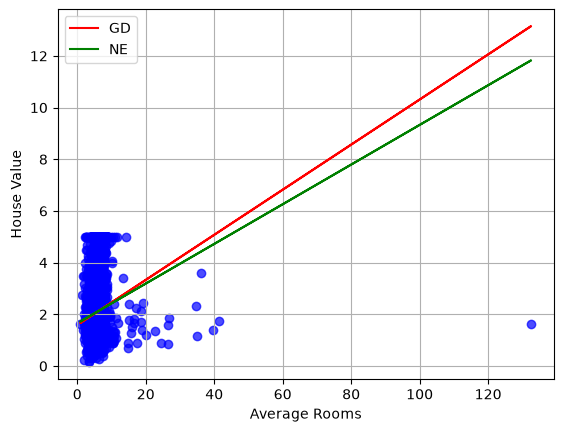

In [126]:
plt.scatter(x_test,y_test,alpha = 0.7,color = 'blue')
plt.plot(x_test,g_pred,color = 'red',label = 'GD')
plt.plot(x_test,ne_pred,color = 'green',label = 'NE')
plt.legend()
plt.grid()
plt.xlabel('Average Rooms')
plt.ylabel('House Value')
plt.show()